In [1]:
import numpy as np
from numpy.fft import fft, fftshift, fftfreq
import matplotlib.pyplot as plt
from scipy import signal

In [2]:
frequency = 10
samples = 100
interpolation_factor = 4
time = np.linspace(0, 1, samples)
time_upsampled = np.linspace(0, 1, samples*interpolation_factor - (interpolation_factor - 1))  
cos_function = np.cos(2*np.pi*frequency*time)

In [3]:
cos_function.shape

(100,)

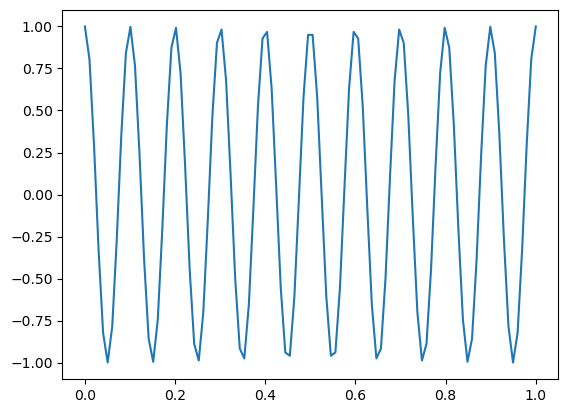

In [4]:
plt.plot(time, cos_function)

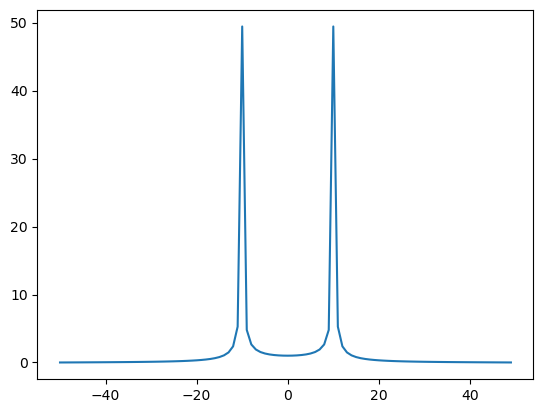

In [5]:
plt.plot(fftshift(fftfreq(samples, d=1/samples)), fftshift(np.abs(fft(cos_function))))

In [6]:
def zero_stuffing(rf_matrices_summed, interpolation_factor):
    interpolation_factor = interpolation_factor - 1
    new_array_length = rf_matrices_summed.shape[0] + interpolation_factor * (rf_matrices_summed.shape[0] - 1)
    new_rf_matrices_summed = np.zeros(new_array_length)
    for k in range(rf_matrices_summed.shape[0]): #for each sample
        idx_new = k + (interpolation_factor * k)
        new_rf_matrices_summed[idx_new] = rf_matrices_summed[k]

    return new_rf_matrices_summed, new_array_length

In [7]:
zero_stuffed_cos, new_array_length = zero_stuffing(cos_function, interpolation_factor)

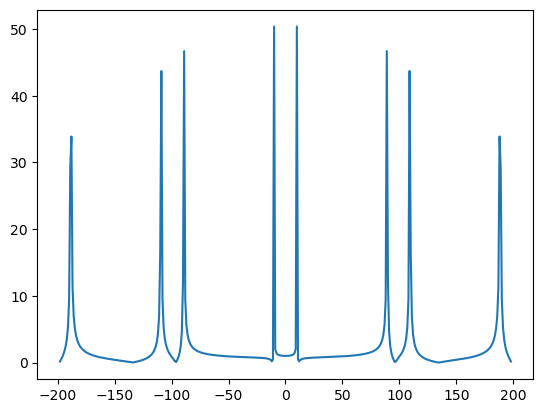

In [8]:
plt.plot(fftshift(fftfreq(zero_stuffed_cos.shape[0], d=1/zero_stuffed_cos.shape[0])), fftshift(np.abs(fft(zero_stuffed_cos))))

In [ ]:
def get_filtered_matrices(zero_stuffed_rf_matrices_summed):
    new_samples = zero_stuffed_rf_matrices_summed.shape[0]
    filtered_rf_matrices_summed = np.zeros((new_samples))
    
    cutoff_freq = 0.50 * 10 #use Nyquist frequency as cutoff frequency
    
    time = np.linspace(-new_samples/2 * 1/new_samples, new_samples/2 * 1/new_samples, new_samples) 
    
    filtering_function = np.sinc(2 *np.pi * cutoff_freq * time)
    filtering_function2 = signal.firwin(new_samples, cutoff_freq, fs=100, window='hamming', pass_zero='lowpass')


    # filtering_function = filtering_function / new_samples / 2
    
    # (convolution in time domain = multiplication in frequency domain)
    filtered_rf_matrices_summed = np.convolve(zero_stuffed_rf_matrices_summed, filtering_function, mode='same')
    filtered_rf_matrices_summed2 = np.convolve(zero_stuffed_rf_matrices_summed, filtering_function2, mode='same')
    
    fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize=(12, 8))

    axes[0,0].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(filtering_function))), label='Filter Response')
    axes[0,0].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(zero_stuffed_rf_matrices_summed))), label='Original Signal')
    axes[0,0].set_title('Frequency Domain')
    
    axes[0,1].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(filtered_rf_matrices_summed))), label='Filtered Signal')
    axes[0,1].set_title('Filtered Result')

    axes[1,0].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(filtering_function2))), label='Filter Response')
    axes[1,0].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(zero_stuffed_rf_matrices_summed))), label='Original Signal')
    axes[1,0].set_title('Frequency Domain')
    
    axes[1,1].plot(fftshift(fftfreq(new_samples, d=1/new_samples)), fftshift(np.abs(fft(filtered_rf_matrices_summed2))), label='Filtered Signal')
    axes[1,1].set_title('Filtered Result')

    fig.tight_layout()
    fig.legend()
    fig.show()
    
    return filtered_rf_matrices_summed, filtered_rf_matrices_summed2

/tmp/ipykernel_46433/1430062715.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


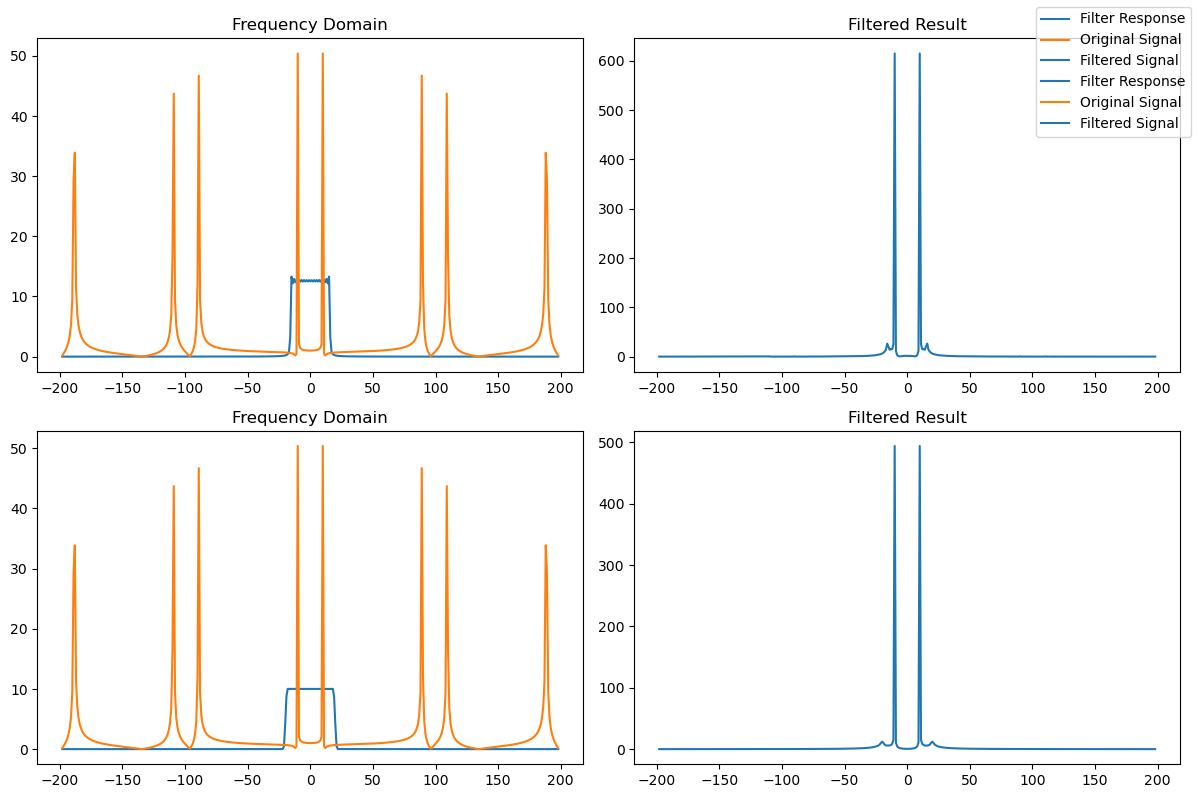

In [10]:
filtered_cos, filtered_cos2  = get_filtered_matrices(zero_stuffed_cos)

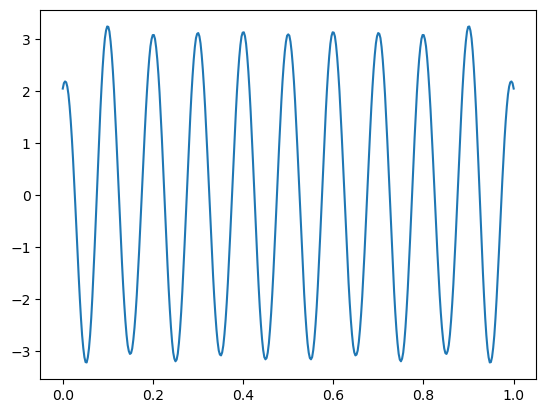

In [11]:
plt.plot(time_upsampled, filtered_cos)

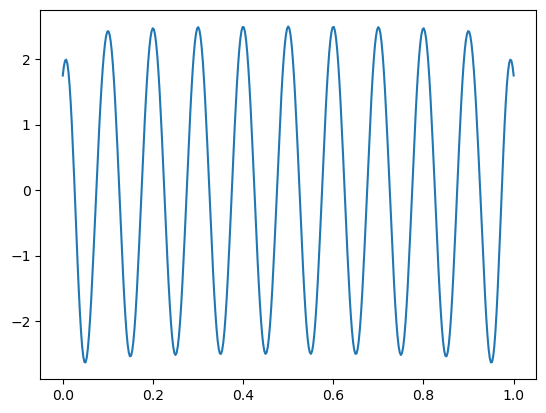

In [12]:
plt.plot(time_upsampled, filtered_cos2)	